In [1]:
"""
NOTEBOOK 2B.2 - ROAR Full Retrain (Fase 2B Faithfulness Gold Standard)
IndoMeme-XAI

Per metode (IG, Cross-Attn, Rollout, Incongruity, Random) x level (10, 20, 30):
  1. Mask top-K% features di train+test berdasarkan attribution
  2. Retrain model dari scratch (encoder frozen, fusion+head random)
  3. Eval di test masked, compare F1 vs baseline (mask 0%) & random
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"
CKPT_PATH    = Path("/kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt")

# Test attributions dari 2A (pre-computed di Fase 2A)
TEST_ATTR_PATHS = {
    "ig_text":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_attributions.npz"),
    "cross_attn":  Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a2-cross-attn/xai_2A2_cross_attention/cross_attn_maps.npz"),
    "rollout":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a3-rollout/xai_2A3_attention_rollout/rollout_maps.npz"),
    "incongruity": Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a4-incongruity/xai_2A4_incongruity_heatmap/incongruity_maps.npz"),
}

OUTPUT_DIR  = Path("/kaggle/working/xai_2B2_roar")
TRAIN_ATTR_DIR = OUTPUT_DIR / "train_attributions"
RETRAIN_DIR    = OUTPUT_DIR / "retrains"
for d in [OUTPUT_DIR, TRAIN_ATTR_DIR, RETRAIN_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id           = "2B.2_roar_retrain",
    seed             = 42,

    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 4,
    topic_emb_dim    = 32,
    head_hidden      = 256,
    dropout          = 0.3,
    icam_num_heads   = 8,
    icam_dropout     = 0.1,
    supcon_proj_hidden  = 128,
    supcon_proj_out     = 128,
    max_seq_len      = 128,

    # ROAR subset & retrain config
    roar_train_size  = 2000,         # subset of train (3415) for compute efficiency
    roar_seed        = 42,
    grid_size        = 14,
    img_size         = 224,
    patch_size       = 16,

    # Retrain hyperparams (lebih ringan dari Fase 1)
    batch_size       = 32,
    grad_accum       = 2,
    num_epochs       = 8,            # was 15 di Fase 1, dikurangi utk 19 retrains
    early_stop_pat   = 4,
    grad_clip        = 1.0,
    lr_encoder       = 1e-5,
    lr_fusion        = 3e-5,
    lr_head          = 5e-5,
    weight_decay     = 0.01,
    warmup_ratio     = 0.10,
    focal_gamma      = 2.0,
    label_smoothing  = 0.1,
    class_weights    = [0.76, 1.46],
    supcon_lambda          = 0.3,
    supcon_temperature     = 0.07,
    supcon_warmup_epochs   = 2,      # 2 epoch focal-only (was 3 di Fase 1)

    # IG params utk training set
    ig_n_steps       = 50,
    ig_internal_bs   = 8,
    ig_outer_bs      = 4,

    # ROAR levels
    mask_levels      = [0.10, 0.20, 0.30],
)

print(f"Experiment: {CONFIG['exp_id']}")
print(f"ROAR train size: {CONFIG['roar_train_size']}")
print(f"Retrain epochs: {CONFIG['num_epochs']}")
print(f"Mask levels: {CONFIG['mask_levels']}")

Experiment: 2B.2_roar_retrain
ROAR train size: 2000
Retrain epochs: 8
Mask levels: [0.1, 0.2, 0.3]


In [2]:
import subprocess, sys
def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
try: import captum
except ImportError: pip_install("captum"); import captum

import os, json, random, time, math, re, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler

from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score
from captum.attr import LayerIntegratedGradients
from tqdm.auto import tqdm

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 17.3 MB/s eta 0:00:00
Device: cuda


In [3]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu","aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak","ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak","engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena","krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi","klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau","spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget","bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang","skrg":"sekarang","skrng":"sekarang","td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana","gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah","blm":"belum","blom":"belum","lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih","jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu","liat":"lihat","ngeliat":"melihat","denger":"dengar","ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja","sih":"","deh":"","dong":"","kok":"","lah":"","loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya","org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada","thd":"terhadap","ttg":"tentang","abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman","rmh":"rumah","kntr":"kantor","krj":"kerja","ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha","hahaha":"haha","hahahaha":"haha","hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing","anjr":"anjing","anying":"anjing","njir":"anjing","bgsd":"bangsat","bgst":"bangsat","bjir":"anjing","bjg":"bajingan","kntl":"kontol","mmk":"memek","tai":"tahi",
}
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")
SEP_TOKEN = "[SEP]"
def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)
def _normalize_slang(text):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{SLANG_DICT.get(core.lower(), core)}{suffix}")
    return " ".join(out)
def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()
def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

In [4]:
df = pd.read_csv(CSV_PATH)
df["label"] = df["hate_final"].map({"not hate": 0, "hate": 1})
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

TOPIC_LIST = ["political","national origin","individual","institutions","gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)
def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec
df["topic_multihot"] = df["topic"].apply(topic_to_multihot)

df_train_full = df[df["split"] == "train"].copy().reset_index(drop=True)
df_val   = df[df["split"] == "validation"].copy().reset_index(drop=True) if "validation" in df["split"].unique() else df[df["split"] == "val"].copy().reset_index(drop=True)
df_test  = df[df["split"] == "test"].copy().reset_index(drop=True)

# Stratified subsample 2000 for ROAR
rng = np.random.RandomState(CONFIG["roar_seed"])
n_target = CONFIG["roar_train_size"]
hate_idx     = df_train_full[df_train_full["label"] == 1].index.values
not_hate_idx = df_train_full[df_train_full["label"] == 0].index.values
n_hate     = int(n_target * (len(hate_idx) / len(df_train_full)))
n_not_hate = n_target - n_hate
sel_hate     = rng.choice(hate_idx,     size=n_hate,     replace=False)
sel_not_hate = rng.choice(not_hate_idx, size=n_not_hate, replace=False)
sel_idx = np.concatenate([sel_hate, sel_not_hate])
rng.shuffle(sel_idx)
df_train_roar = df_train_full.iloc[sel_idx].reset_index(drop=True)

print(f"Train ROAR: {len(df_train_roar)}  (hate {(df_train_roar.label==1).sum()}, not {(df_train_roar.label==0).sum()})")
print(f"Val: {len(df_val)}  Test: {len(df_test)}")

Train ROAR: 2000  (hate 686, not 1314)
Val: 603  Test: 1005


In [5]:
tokenizer       = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
image_processor = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])
IMG_MEAN = image_processor.image_mean
IMG_STD  = image_processor.image_std

TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

class IndoMemeDataset(Dataset):
    """Dataset dengan opsi runtime-masking via attribution."""
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128,
                 mask_method=None, mask_level=0.0,
                 token_l2_arr=None, image_maps_arr=None,
                 idxs_arr=None, special_token_ids=None,
                 grid_size=14, patch_size=16, rng_seed=0):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len
        self.mask_method = mask_method
        self.mask_level  = mask_level
        self.grid_size   = grid_size
        self.patch_size  = patch_size
        self.special_token_ids = special_token_ids or {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id}
        self.rng_seed    = rng_seed

        # Attribution arrays (need to map self.df idx -> attribution row)
        if mask_method in ("ig_text",):
            self.idx_to_attr = {int(i): k for k, i in enumerate(idxs_arr)}
            self.token_l2_arr = token_l2_arr
        elif mask_method in ("cross_attn", "rollout", "incongruity"):
            self.idx_to_attr = {int(i): k for k, i in enumerate(idxs_arr)}
            self.image_maps_arr = image_maps_arr
        else:
            self.idx_to_attr = None

    def __len__(self): return len(self.df)

    def _mask_text(self, input_ids, attention_mask, sample_idx):
        if self.mask_method == "ig_text":
            row = self.idx_to_attr.get(int(sample_idx))
            if row is None: return input_ids, attention_mask
            scores = self.token_l2_arr[row].copy()
        elif self.mask_method == "random":
            scores = None
        else:
            return input_ids, attention_mask

        T = input_ids.shape[0]
        is_real = attention_mask.numpy() == 1
        is_special = np.array([int(t) in self.special_token_ids for t in input_ids.numpy()])
        eligible = is_real & ~is_special
        n_eligible = int(eligible.sum())
        n_mask = max(1, int(round(n_eligible * self.mask_level)))
        if n_mask >= n_eligible: return input_ids, attention_mask

        if scores is not None:
            scores[~eligible] = -np.inf
            top = np.argpartition(-scores, n_mask)[:n_mask]
        else:
            rng = np.random.RandomState(self.rng_seed + int(sample_idx))
            elig_idx = np.where(eligible)[0]
            top = rng.choice(elig_idx, size=n_mask, replace=False)

        new_mask = attention_mask.clone()
        new_mask[top] = 0
        return input_ids, new_mask

    def _mask_image(self, pixel_tensor, sample_idx):
        G, P = self.grid_size, self.patch_size
        n_total = G * G
        n_mask  = max(1, int(round(n_total * self.mask_level)))
        if self.mask_method in ("cross_attn", "rollout", "incongruity"):
            row = self.idx_to_attr.get(int(sample_idx))
            if row is None: return pixel_tensor
            flat = self.image_maps_arr[row].flatten()
            top = np.argpartition(-flat, n_mask)[:n_mask]
        elif self.mask_method == "random":
            rng = np.random.RandomState(self.rng_seed + int(sample_idx))
            top = rng.choice(n_total, size=n_mask, replace=False)
        else:
            return pixel_tensor
        rows = top // G; cols = top % G
        new_pv = pixel_tensor.clone()
        for r, c in zip(rows, cols):
            r0, r1 = int(r) * P, (int(r) + 1) * P
            c0, c1 = int(c) * P, (int(c) + 1) * P
            new_pv[:, r0:r1, c0:c1] = 0.0
        return new_pv

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row["text_input"], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        input_ids = enc["input_ids"].squeeze(0)
        attn_mask = enc["attention_mask"].squeeze(0)
        sample_idx = int(row["idx"])

        # Apply masking (no-op kalau mask_method=None)
        if self.mask_method in ("ig_text", "random") and self.mask_level > 0:
            if self.mask_method == "random" and getattr(self, "_mask_domain", "text") == "text":
                input_ids, attn_mask = self._mask_text(input_ids, attn_mask, sample_idx)
            elif self.mask_method == "ig_text":
                input_ids, attn_mask = self._mask_text(input_ids, attn_mask, sample_idx)
        if self.mask_method in ("cross_attn", "rollout", "incongruity") and self.mask_level > 0:
            img_tensor = self._mask_image(img_tensor, sample_idx)
        if self.mask_method == "random" and getattr(self, "_mask_domain", "text") == "image" and self.mask_level > 0:
            img_tensor = self._mask_image(img_tensor, sample_idx)

        return {
            "input_ids":      input_ids,
            "attention_mask": attn_mask,
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            sample_idx,
        }

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [6]:
class ICAMFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()
        self.t2i_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.gate_relevant    = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gate_incongruent = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fusion_proj = nn.Linear(hidden_dim, hidden_dim)
        self.layer_norm  = nn.LayerNorm(hidden_dim)
        self.save_attn = False
        self.last_t2i_attn = self.last_i2t_attn = None
        self.last_incongruity = self.last_g1 = self.last_g2 = None

    def forward(self, text_h, image_h, text_mask=None):
        text_kpm = (~text_mask.bool()) if text_mask is not None else None
        t2i_out, t2i_w = self.t2i_attn(text_h, image_h, image_h, key_padding_mask=None, need_weights=self.save_attn, average_attn_weights=True)
        i2t_out, i2t_w = self.i2t_attn(image_h, text_h, text_h, key_padding_mask=text_kpm, need_weights=self.save_attn, average_attn_weights=True)
        h_image_pooled = i2t_out.mean(dim=1)
        text_norm  = F.normalize(text_h,  dim=-1); image_norm = F.normalize(image_h, dim=-1)
        sim         = torch.bmm(text_norm, image_norm.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w       = F.softmax(incongruity, dim=-1)
        h_inc       = torch.bmm(inc_w, image_h)
        if text_mask is not None:
            m = text_mask.unsqueeze(-1).float()
            h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        else:
            h_inc_pooled = h_inc.mean(dim=1)
        h_text = text_h[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(   torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled  ], dim=-1)))
        fused   = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        h_fused = self.layer_norm(self.fusion_proj(fused))
        if self.save_attn:
            self.last_t2i_attn = t2i_w.detach() if t2i_w is not None else None
            self.last_i2t_attn = i2t_w.detach() if i2t_w is not None else None
            self.last_incongruity = incongruity.detach()
            self.last_g1 = g1.detach(); self.last_g2 = g2.detach()
        return h_fused, g1.mean().item(), g2.mean().item()


class ICAMHateModelSupCon(nn.Module):
    def __init__(self, cfg, image_attn_impl="sdpa"):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(cfg["image_model_name"], attn_implementation=image_attn_impl)
        self._freeze_bottom(self.text_encoder.encoder.layer,  cfg["freeze_n_layers"])
        self._freeze_bottom(self.image_encoder.encoder.layer, cfg["freeze_n_layers"])
        for p in self.text_encoder.embeddings.parameters():  p.requires_grad = False
        for p in self.image_encoder.embeddings.parameters(): p.requires_grad = False
        hidden = self.text_encoder.config.hidden_size
        self.icam = ICAMFusion(hidden_dim=hidden, num_heads=cfg["icam_num_heads"], dropout=cfg["icam_dropout"])
        self.supcon_proj = nn.Sequential(
            nn.Linear(hidden, cfg["supcon_proj_hidden"]), nn.ReLU(),
            nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
        )
        self.topic_proj = nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())
        head_in = hidden + cfg["topic_emb_dim"]
        self.head = nn.Sequential(
            nn.Linear(head_in, cfg["head_hidden"]), nn.GELU(),
            nn.Dropout(cfg["dropout"]), nn.Linear(cfg["head_hidden"], 2),
        )

    @staticmethod
    def _freeze_bottom(layers, n):
        for i, layer in enumerate(layers):
            if i < n:
                for p in layer.parameters(): p.requires_grad = False

    def forward(self, input_ids, attention_mask, pixel_values, topic, output_attentions=False):
        t_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i_out = self.image_encoder(pixel_values=pixel_values, output_attentions=output_attentions)
        h_fused, g1m, g2m = self.icam(t_out.last_hidden_state, i_out.last_hidden_state, attention_mask)
        supcon_features = F.normalize(self.supcon_proj(h_fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits    = self.head(torch.cat([h_fused, topic_emb], dim=-1))
        if output_attentions:
            return logits, supcon_features, g1m, g2m, i_out.attentions
        return logits, supcon_features, g1m, g2m

In [7]:
"""
Compute attribution untuk training subset ROAR.
Cache per metode di TRAIN_ATTR_DIR. Skip kalau sudah ada.
"""

train_attr_files = {
    "ig_text":     TRAIN_ATTR_DIR / "ig_train.npz",
    "cross_attn":  TRAIN_ATTR_DIR / "cross_attn_train.npz",
    "rollout":     TRAIN_ATTR_DIR / "rollout_train.npz",
    "incongruity": TRAIN_ATTR_DIR / "incongruity_train.npz",
}

need_compute = any(not p.exists() for p in train_attr_files.values())
print(f"Train attributions to compute: {[k for k, p in train_attr_files.items() if not p.exists()]}")

if need_compute:
    print("\nLoading frozen seed=7 model for attribution extraction...")
    model_for_attr = ICAMHateModelSupCon(CONFIG, image_attn_impl="eager").to(DEVICE)
    ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
    state = ckpt["state_dict"] if (isinstance(ckpt, dict) and "state_dict" in ckpt) else ckpt
    model_for_attr.load_state_dict(state, strict=False)
    for p in model_for_attr.parameters(): p.requires_grad = False
    model_for_attr.eval()

    # Dataset utk attribution (no masking)
    ds_train_attr = IndoMemeDataset(df_train_roar, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"])
    dl_train_attr = DataLoader(ds_train_attr, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
else:
    print("All train attributions cached, skipping Phase A.")

Train attributions to compute: ['ig_text', 'cross_attn', 'rollout', 'incongruity']

Loading frozen seed=7 model for attribution extraction...


pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

In [8]:
def attention_rollout(attentions, head_fusion="mean"):
    result = None
    device = attentions[0].device
    B, H, T, _ = attentions[0].shape
    eye = torch.eye(T, device=device).unsqueeze(0).expand(B, -1, -1)
    for attn in attentions:
        fused = attn.mean(dim=1) if head_fusion == "mean" else attn.max(dim=1).values
        rolled = fused + eye
        rolled = rolled / rolled.sum(dim=-1, keepdim=True).clamp(min=1e-12)
        result = rolled if result is None else torch.bmm(rolled, result)
    return result[:, 0, 1:]  # CLS row, drop CLS itself


if need_compute and not all(train_attr_files[k].exists() for k in ["cross_attn","rollout","incongruity"]):
    print("\n[Phase A.1] Image attributions on train ROAR subset...")
    model_for_attr.icam.save_attn = True

    all_cross, all_rollout, all_inc_sm, all_idxs = [], [], [], []
    G = CONFIG["grid_size"]

    for batch in tqdm(dl_train_attr, desc="image attrib"):
        input_ids      = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        pixel_values   = batch["pixel_values"].to(DEVICE)
        topic          = batch["topic"].to(DEVICE)

        with torch.no_grad():
            logits, _, _, _, attns = model_for_attr(input_ids, attention_mask, pixel_values, topic, output_attentions=True)

        # Cross-Attn
        t2i = model_for_attr.icam.last_t2i_attn.float()                        # [B, T, P]
        mask_f = attention_mask.float().unsqueeze(-1)
        ca_avg = (t2i * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)  # [B, P]
        ca_maps = ca_avg[:, 1:].reshape(-1, G, G)

        # Rollout
        cls_rel = attention_rollout(attns)
        rl_maps = cls_rel.reshape(-1, G, G)

        # Incongruity (softmax)
        raw = model_for_attr.icam.last_incongruity.float()
        sm_w = F.softmax(raw, dim=-1)
        sm_avg = (sm_w * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)
        inc_maps = sm_avg[:, 1:].reshape(-1, G, G)

        all_cross.append(ca_maps.cpu().numpy())
        all_rollout.append(rl_maps.cpu().numpy())
        all_inc_sm.append(inc_maps.cpu().numpy())
        all_idxs.extend(batch["idx"].tolist())

    all_cross   = np.concatenate(all_cross,   axis=0).astype(np.float32)
    all_rollout = np.concatenate(all_rollout, axis=0).astype(np.float32)
    all_inc_sm  = np.concatenate(all_inc_sm,  axis=0).astype(np.float32)
    all_idxs    = np.array(all_idxs, dtype=np.int64)

    np.savez_compressed(train_attr_files["cross_attn"],  maps_14x14=all_cross,   idxs=all_idxs)
    np.savez_compressed(train_attr_files["rollout"],     maps_14x14=all_rollout, idxs=all_idxs)
    np.savez_compressed(train_attr_files["incongruity"], maps_softmax_14x14=all_inc_sm, idxs=all_idxs)
    print(f"  Saved cross_attn, rollout, incongruity train attributions ({len(all_idxs)} samples)")
    model_for_attr.icam.save_attn = False


[Phase A.1] Image attributions on train ROAR subset...


image attrib:   0%|          | 0/63 [00:00<?, ?it/s]

  Saved cross_attn, rollout, incongruity train attributions (2000 samples)


In [9]:
if need_compute and not train_attr_files["ig_text"].exists():
    print("\n[Phase A.2] IG (text) on train ROAR subset (heaviest step ~15-20 min)...")

    text_embed_layer = model_for_attr.text_encoder.embeddings
    
    class _ModelForCaptum(nn.Module):
        def __init__(self, base): super().__init__(); self.base = base
        def forward(self, input_ids, attention_mask, pixel_values, topic):
            logits, _, _, _ = self.base(input_ids, attention_mask, pixel_values, topic)
            return logits

    model_captum = _ModelForCaptum(model_for_attr).to(DEVICE)
    lig = LayerIntegratedGradients(model_captum, text_embed_layer)

    dl_train_ig = DataLoader(ds_train_attr, batch_size=CONFIG["ig_outer_bs"], shuffle=False, num_workers=2, pin_memory=True)

    all_token_l2, all_attn_mask, all_idxs = [], [], []
    for batch in tqdm(dl_train_ig, desc="IG train"):
        input_ids      = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        pixel_values   = batch["pixel_values"].to(DEVICE)
        topic          = batch["topic"].to(DEVICE)
        baseline_ids   = torch.full_like(input_ids, tokenizer.pad_token_id)
        with torch.no_grad():
            logits = model_captum(input_ids, attention_mask, pixel_values, topic)
            preds = logits.argmax(dim=-1)
        atts = lig.attribute(
            inputs=input_ids, baselines=baseline_ids,
            additional_forward_args=(attention_mask, pixel_values, topic),
            target=preds, n_steps=CONFIG["ig_n_steps"],
            internal_batch_size=CONFIG["ig_internal_bs"],
        )
        token_l2 = atts.norm(dim=-1).cpu().numpy()
        all_token_l2.append(token_l2)
        all_attn_mask.append(attention_mask.cpu().numpy().astype(np.int8))
        all_idxs.extend(batch["idx"])

    all_token_l2  = np.concatenate(all_token_l2,  axis=0).astype(np.float32)
    all_attn_mask = np.concatenate(all_attn_mask, axis=0)
    all_idxs      = np.array(all_idxs, dtype=np.int64)

    np.savez_compressed(train_attr_files["ig_text"],
                         token_l2=all_token_l2, attention_mask=all_attn_mask, idxs=all_idxs)
    print(f"  Saved IG train attribution ({len(all_idxs)} samples)")

# Cleanup attribution model dari memory
if need_compute:
    del model_for_attr
    if 'model_captum' in dir(): del model_captum
    torch.cuda.empty_cache()
print("\nPhase A complete.")


[Phase A.2] IG (text) on train ROAR subset (heaviest step ~15-20 min)...


IG train:   0%|          | 0/500 [00:00<?, ?it/s]

  Saved IG train attribution (2000 samples)

Phase A complete.


In [10]:
train_attr = {}
for name, path in train_attr_files.items():
    d = np.load(path)
    if name == "ig_text":
        train_attr[name] = {"token_l2": d["token_l2"], "att_mask": d["attention_mask"], "idxs": d["idxs"]}
    elif name == "incongruity":
        train_attr[name] = {"maps_14x14": d["maps_softmax_14x14"], "idxs": d["idxs"]}
    else:
        train_attr[name] = {"maps_14x14": d["maps_14x14"], "idxs": d["idxs"]}
    print(f"train {name:12s}: {next(iter(train_attr[name].values())).shape}")

test_attr = {}
for name, path in TEST_ATTR_PATHS.items():
    d = np.load(path)
    if name == "ig_text":
        test_attr[name] = {"token_l2": d["token_l2"], "att_mask": d["attention_mask"], "idxs": d["idxs"]}
    elif name == "incongruity":
        test_attr[name] = {"maps_14x14": d["maps_softmax_14x14"], "idxs": d["idxs"]}
    else:
        test_attr[name] = {"maps_14x14": d["maps_14x14"], "idxs": d["idxs"]}
    print(f"test  {name:12s}: {next(iter(test_attr[name].values())).shape}")

train ig_text     : (2000, 128)
train cross_attn  : (2000, 14, 14)
train rollout     : (2000, 14, 14)
train incongruity : (2000, 14, 14)
test  ig_text     : (1005, 128)
test  cross_attn  : (1005, 14, 14)
test  rollout     : (1005, 14, 14)
test  incongruity : (1005, 14, 14)


In [11]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.0, num_classes=2):
        super().__init__()
        self.gamma, self.label_smoothing, self.num_classes = gamma, label_smoothing, num_classes
        if alpha is not None:
            self.register_buffer("alpha", torch.tensor(alpha, dtype=torch.float32))
        else: self.alpha = None
    def forward(self, logits, target):
        log_probs = F.log_softmax(logits, dim=-1); probs = log_probs.exp()
        with torch.no_grad():
            true_dist = torch.full_like(log_probs, self.label_smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, target.unsqueeze(1), 1.0 - self.label_smoothing)
        pt = probs.gather(1, target.unsqueeze(1)).squeeze(1).clamp(min=1e-8)
        focal_w = (1.0 - pt) ** self.gamma
        ce = -(true_dist * log_probs).sum(dim=-1)
        loss = focal_w * ce
        if self.alpha is not None: loss = self.alpha.to(logits.device)[target] * loss
        return loss.mean()

class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__(); self.temperature = temperature
    def forward(self, features, labels):
        device = features.device; B = features.size(0)
        sim = torch.matmul(features, features.T) / self.temperature
        sim_max, _ = sim.max(dim=1, keepdim=True)
        sim = sim - sim_max.detach()
        labels = labels.contiguous().view(-1, 1)
        mask_pos = (labels == labels.T).float().to(device)
        eye = torch.eye(B, device=device); mask_pos = mask_pos - eye
        mask_all = 1.0 - eye
        exp_sim = torch.exp(sim) * mask_all
        log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)
        n_pos = mask_pos.sum(dim=1)
        mean_log = (mask_pos * log_prob).sum(dim=1) / n_pos.clamp(min=1.0)
        valid = (n_pos > 0).float()
        return -(mean_log * valid).sum() / valid.sum().clamp(min=1.0)

focal_criterion  = FocalLoss(gamma=CONFIG["focal_gamma"], alpha=CONFIG["class_weights"], label_smoothing=CONFIG["label_smoothing"])
supcon_criterion = SupConLoss(temperature=CONFIG["supcon_temperature"])

In [12]:
def build_optimizer_scheduler(model, cfg, num_training_steps):
    enc_p, fusion_p, head_p = [], [], []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if n.startswith(("text_encoder","image_encoder")): enc_p.append(p)
        elif n.startswith("icam"): fusion_p.append(p)
        else: head_p.append(p)
    groups = [
        {"params": enc_p,    "lr": cfg["lr_encoder"], "weight_decay": cfg["weight_decay"]},
        {"params": fusion_p, "lr": cfg["lr_fusion"],  "weight_decay": cfg["weight_decay"]},
        {"params": head_p,   "lr": cfg["lr_head"],    "weight_decay": cfg["weight_decay"]},
    ]
    optimizer = torch.optim.AdamW(groups)
    num_warmup = int(cfg["warmup_ratio"] * num_training_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup, num_training_steps)
    return optimizer, scheduler


def train_one_epoch(model, loader, optimizer, scheduler, focal_fn, supcon_fn, scaler, cfg, epoch):
    model.train()
    total_focal = total_supcon = 0.0; n = 0
    supcon_active = epoch > cfg["supcon_warmup_epochs"]
    optimizer.zero_grad()
    for step, batch in enumerate(loader):
        input_ids      = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
        pixel_values   = batch["pixel_values"].to(DEVICE, non_blocking=True)
        topic          = batch["topic"].to(DEVICE, non_blocking=True)
        labels_b       = batch["label"].to(DEVICE, non_blocking=True)
        with autocast(device_type="cuda"):
            logits, supcon_feats, g1m, g2m = model(input_ids, attention_mask, pixel_values, topic)
            L_focal = focal_fn(logits, labels_b)
            if supcon_active:
                L_supcon = supcon_fn(supcon_feats, labels_b)
                loss_total = L_focal + cfg["supcon_lambda"] * L_supcon
            else:
                L_supcon = torch.tensor(0.0, device=DEVICE)
                loss_total = L_focal
            loss = loss_total / cfg["grad_accum"]
        scaler.scale(loss).backward()
        bs = labels_b.size(0)
        total_focal += L_focal.item() * bs; total_supcon += L_supcon.item() * bs; n += bs
        if (step + 1) % cfg["grad_accum"] == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], cfg["grad_clip"])
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad()
    return total_focal / max(n, 1), total_supcon / max(n, 1)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
        pixel_values = batch["pixel_values"].to(DEVICE, non_blocking=True)
        topic = batch["topic"].to(DEVICE, non_blocking=True)
        with autocast(device_type="cuda"):
            logits, _, _, _ = model(input_ids, attention_mask, pixel_values, topic)
        all_logits.append(logits.float().cpu()); all_labels.append(batch["label"])
    logits = torch.cat(all_logits); labels = torch.cat(all_labels).numpy()
    probs = F.softmax(logits, dim=-1).numpy()
    preds = probs.argmax(axis=-1)
    return {
        "macro_f1":   float(f1_score(labels, preds, average="macro")),
        "accuracy":   float(accuracy_score(labels, preds)),
        "hate_p":     float(precision_score(labels, preds, pos_label=1, zero_division=0)),
        "hate_r":     float(recall_score(labels, preds, pos_label=1, zero_division=0)),
        "hate_f1":    float(f1_score(labels, preds, pos_label=1, zero_division=0)),
    }

In [13]:
RETRAIN_CONFIGS = []
RETRAIN_CONFIGS.append({"name": "baseline_no_mask", "method": None, "level": 0.0, "domain": None})

# Text retrains
for lv in CONFIG["mask_levels"]:
    pct = int(lv * 100)
    RETRAIN_CONFIGS.append({"name": f"ig_{pct}",          "method": "ig_text", "level": lv, "domain": "text"})
    RETRAIN_CONFIGS.append({"name": f"random_text_{pct}", "method": "random",  "level": lv, "domain": "text"})

# Image retrains
for lv in CONFIG["mask_levels"]:
    pct = int(lv * 100)
    for m in ["cross_attn", "rollout", "incongruity"]:
        RETRAIN_CONFIGS.append({"name": f"{m}_{pct}", "method": m, "level": lv, "domain": "image"})
    RETRAIN_CONFIGS.append({"name": f"random_image_{pct}", "method": "random", "level": lv, "domain": "image"})

print(f"Total retrains: {len(RETRAIN_CONFIGS)}")
for cfg_r in RETRAIN_CONFIGS: print(f"  {cfg_r['name']}")

Total retrains: 19
  baseline_no_mask
  ig_10
  random_text_10
  ig_20
  random_text_20
  ig_30
  random_text_30
  cross_attn_10
  rollout_10
  incongruity_10
  random_image_10
  cross_attn_20
  rollout_20
  incongruity_20
  random_image_20
  cross_attn_30
  rollout_30
  incongruity_30
  random_image_30


In [14]:
def build_masked_loaders(method, level, domain):
    """Create train+test loaders with masking applied per the method."""
    # Setup attribution arrays
    train_kw, test_kw = {}, {}
    if method == "ig_text":
        train_kw = {"token_l2_arr": train_attr["ig_text"]["token_l2"], "idxs_arr": train_attr["ig_text"]["idxs"]}
        test_kw  = {"token_l2_arr": test_attr["ig_text"]["token_l2"],  "idxs_arr": test_attr["ig_text"]["idxs"]}
    elif method in ("cross_attn", "rollout", "incongruity"):
        train_kw = {"image_maps_arr": train_attr[method]["maps_14x14"], "idxs_arr": train_attr[method]["idxs"]}
        test_kw  = {"image_maps_arr": test_attr[method]["maps_14x14"],  "idxs_arr": test_attr[method]["idxs"]}

    ds_tr = IndoMemeDataset(df_train_roar, tokenizer, TRAIN_TRANSFORM, CONFIG["max_seq_len"],
                             mask_method=method, mask_level=level, **train_kw)
    ds_te = IndoMemeDataset(df_test, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"],
                             mask_method=method, mask_level=level, **test_kw)

    if method == "random":
        ds_tr._mask_domain = domain; ds_te._mask_domain = domain

    # Sampler: WeightedRandomSampler utk class balance
    labels_tr = df_train_roar["label"].values
    class_count = np.bincount(labels_tr, minlength=2)
    sample_w = 1.0 / class_count[labels_tr]
    g = torch.Generator(); g.manual_seed(CONFIG["roar_seed"])
    sampler = WeightedRandomSampler(weights=torch.from_numpy(sample_w).double(),
                                     num_samples=len(sample_w), replacement=True, generator=g)

    dl_tr = DataLoader(ds_tr, batch_size=CONFIG["batch_size"], sampler=sampler, num_workers=2, pin_memory=True)
    dl_te = DataLoader(ds_te, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
    return dl_tr, dl_te

In [15]:
all_results = {}

for r_cfg in RETRAIN_CONFIGS:
    name = r_cfg["name"]
    result_path = RETRAIN_DIR / f"{name}.json"

    if result_path.exists():
        with open(result_path) as f: all_results[name] = json.load(f)
        print(f"[skip] {name}: cached.")
        continue

    print(f"\n{'='*60}\nRETRAIN: {name}\n{'='*60}")
    set_seed(CONFIG["roar_seed"])

    dl_train, dl_test = build_masked_loaders(r_cfg["method"], r_cfg["level"], r_cfg["domain"])

    model = ICAMHateModelSupCon(CONFIG, image_attn_impl="sdpa").to(DEVICE)
    n_steps = math.ceil(len(dl_train) / CONFIG["grad_accum"]) * CONFIG["num_epochs"]
    optimizer, scheduler = build_optimizer_scheduler(model, CONFIG, n_steps)
    scaler = GradScaler("cuda")

    best_val_f1, best_epoch, no_improve = -1.0, 0, 0
    best_test_metrics = None
    t0 = time.time()

    for epoch in range(1, CONFIG["num_epochs"] + 1):
        focal_l, supcon_l = train_one_epoch(model, dl_train, optimizer, scheduler,
                                             focal_criterion, supcon_criterion, scaler, CONFIG, epoch)
        # eval di test masked
        test_metrics = evaluate_model(model, dl_test)
        score = test_metrics["macro_f1"]
        print(f"  ep{epoch:02d} focal={focal_l:.3f} supcon={supcon_l:.3f} test_F1={score:.4f}")

        if score > best_val_f1:
            best_val_f1 = score; best_epoch = epoch; no_improve = 0
            best_test_metrics = test_metrics
        else:
            no_improve += 1
            if no_improve >= CONFIG["early_stop_pat"]:
                print(f"  early stopping ep{epoch}")
                break

    elapsed = time.time() - t0
    result = {
        "name":     name,
        "method":   r_cfg["method"],
        "level":    r_cfg["level"],
        "domain":   r_cfg["domain"],
        "best_epoch":  best_epoch,
        "best_test_F1": float(best_val_f1),
        "test_metrics": best_test_metrics,
        "elapsed_min":  elapsed / 60,
    }
    with open(result_path, "w") as f: json.dump(result, f, indent=2)
    all_results[name] = result
    print(f"  done {name}: F1={best_val_f1:.4f}  ({elapsed/60:.1f} min)")

    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()

print(f"\n{'='*60}\nALL RETRAINS DONE\n{'='*60}")


RETRAIN: baseline_no_mask


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  ep01 focal=0.184 supcon=0.000 test_F1=0.6218
  ep02 focal=0.132 supcon=0.000 test_F1=0.7390
  ep03 focal=0.121 supcon=3.471 test_F1=0.7680
  ep04 focal=0.114 supcon=3.334 test_F1=0.7686
  ep05 focal=0.107 supcon=3.308 test_F1=0.7680
  ep06 focal=0.100 supcon=3.286 test_F1=0.7776
  ep07 focal=0.100 supcon=3.287 test_F1=0.7760
  ep08 focal=0.088 supcon=3.254 test_F1=0.7790
  done baseline_no_mask: F1=0.7790  (4.5 min)

RETRAIN: ig_10


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (68 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  ep01 focal=0.183 supcon=0.000 test_F1=0.5968
  ep02 focal=0.132 supcon=0.000 test_F1=0.7402
  ep03 focal=0.121 supcon=3.472 test_F1=0.7678
  ep04 focal=0.114 supcon=3.335 test_F1=0.7681
  ep05 focal=0.107 supcon=3.311 test_F1=0.7710
  ep06 focal=0.101 supcon=3.290 test_F1=0.7750
  ep07 focal=0.101 supcon=3.293 test_F1=0.7724
  ep08 focal=0.090 supcon=3.260 test_F1=0.7783
  done random_image_30: F1=0.7783  (4.7 min)

ALL RETRAINS DONE


In [16]:
rows = []
baseline_f1 = all_results["baseline_no_mask"]["best_test_F1"]
for r_cfg in RETRAIN_CONFIGS:
    res = all_results[r_cfg["name"]]
    tm = res["test_metrics"]
    rows.append({
        "name":      r_cfg["name"],
        "method":    r_cfg["method"] or "baseline",
        "domain":    r_cfg["domain"] or "-",
        "level":     r_cfg["level"],
        "test_F1":   tm["macro_f1"],
        "delta_F1":  tm["macro_f1"] - baseline_f1,
        "hate_R":    tm["hate_r"],
        "hate_F1":   tm["hate_f1"],
        "accuracy":  tm["accuracy"],
        "best_epoch": res["best_epoch"],
        "min":       res["elapsed_min"],
    })
df_results = pd.DataFrame(rows)
df_results.to_csv(OUTPUT_DIR / "roar_results_full.csv", index=False)
print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))

            name      method domain  level  test_F1  delta_F1  hate_R  hate_F1  accuracy  best_epoch    min
baseline_no_mask    baseline      - 0.0000   0.7790    0.0000  0.7608   0.7193    0.7950           8 4.4891
           ig_10     ig_text   text 0.1000   0.7588   -0.0202  0.7666   0.7000    0.7731           7 4.6518
  random_text_10      random   text 0.1000   0.7719   -0.0070  0.7666   0.7131    0.7871           8 4.7251
           ig_20     ig_text   text 0.2000   0.7435   -0.0354  0.6715   0.6657    0.7672           6 4.6287
  random_text_20      random   text 0.2000   0.7569   -0.0221  0.7550   0.6959    0.7721           8 4.6524
           ig_30     ig_text   text 0.3000   0.7409   -0.0381  0.6801   0.6648    0.7632           6 4.5686
  random_text_30      random   text 0.3000   0.7507   -0.0282  0.7493   0.6887    0.7662           8 4.5405
   cross_attn_10  cross_attn  image 0.1000   0.7819    0.0029  0.7839   0.7263    0.7960           6 4.5614
      rollout_10     rollout

In [17]:
print(f"\n{'='*72}\nROAR FAITHFULNESS VERDICT\n{'='*72}")
print(f"Baseline (no mask) test F1: {baseline_f1:.4f}\n")

# TEXT
print("[TEXT]")
for lv in [10, 20, 30]:
    f_ig   = all_results[f"ig_{lv}"]["best_test_F1"]
    f_rand = all_results[f"random_text_{lv}"]["best_test_F1"]
    d_ig   = f_ig - baseline_f1
    d_rand = f_rand - baseline_f1
    diff   = d_ig - d_rand
    verdict = "FAITHFUL" if diff < -0.005 else ("WEAK" if diff < 0 else "NOT FAITHFUL")
    print(f"  IG @ {lv}%   : F1={f_ig:.4f} (d={d_ig:+.4f}) | random F1={f_rand:.4f} (d={d_rand:+.4f}) | diff={diff:+.4f} -> {verdict}")

# IMAGE
print("\n[IMAGE]")
for lv in [10, 20, 30]:
    f_rand = all_results[f"random_image_{lv}"]["best_test_F1"]
    d_rand = f_rand - baseline_f1
    print(f"  Random image @ {lv}%: F1={f_rand:.4f} (d={d_rand:+.4f})")
    for method in ["cross_attn", "rollout", "incongruity"]:
        f_m = all_results[f"{method}_{lv}"]["best_test_F1"]
        d_m = f_m - baseline_f1
        diff = d_m - d_rand
        verdict = "FAITHFUL" if diff < -0.005 else ("WEAK" if diff < 0 else "NOT FAITHFUL")
        print(f"    {method:12s}: F1={f_m:.4f} (d={d_m:+.4f}) | diff vs random={diff:+.4f} -> {verdict}")


ROAR FAITHFULNESS VERDICT
Baseline (no mask) test F1: 0.7790

[TEXT]
  IG @ 10%   : F1=0.7588 (d=-0.0202) | random F1=0.7719 (d=-0.0070) | diff=-0.0131 -> FAITHFUL
  IG @ 20%   : F1=0.7435 (d=-0.0354) | random F1=0.7569 (d=-0.0221) | diff=-0.0133 -> FAITHFUL
  IG @ 30%   : F1=0.7409 (d=-0.0381) | random F1=0.7507 (d=-0.0282) | diff=-0.0099 -> FAITHFUL

[IMAGE]
  Random image @ 10%: F1=0.7861 (d=+0.0071)
    cross_attn  : F1=0.7819 (d=+0.0029) | diff vs random=-0.0042 -> WEAK
    rollout     : F1=0.7778 (d=-0.0012) | diff vs random=-0.0083 -> FAITHFUL
    incongruity : F1=0.7807 (d=+0.0017) | diff vs random=-0.0054 -> FAITHFUL
  Random image @ 20%: F1=0.7797 (d=+0.0008)
    cross_attn  : F1=0.7776 (d=-0.0014) | diff vs random=-0.0021 -> WEAK
    rollout     : F1=0.7823 (d=+0.0033) | diff vs random=+0.0026 -> NOT FAITHFUL
    incongruity : F1=0.7773 (d=-0.0016) | diff vs random=-0.0024 -> WEAK
  Random image @ 30%: F1=0.7783 (d=-0.0007)
    cross_attn  : F1=0.7832 (d=+0.0043) | diff vs 

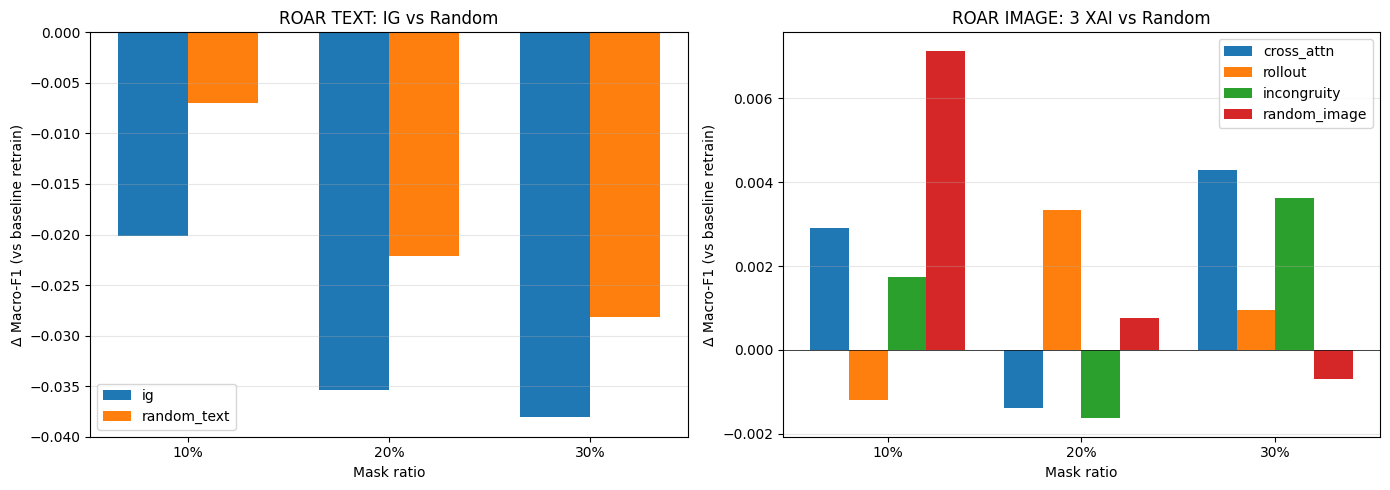

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
levels = [10, 20, 30]

# TEXT
methods_t = ["ig", "random_text"]
x = np.arange(len(levels)); w = 0.35
for i, m in enumerate(methods_t):
    deltas = [all_results[f"{m}_{lv}"]["best_test_F1"] - baseline_f1 for lv in levels]
    axes[0].bar(x + i*w, deltas, w, label=m)
axes[0].set_xticks(x + w/2); axes[0].set_xticklabels([f"{lv}%" for lv in levels])
axes[0].set_xlabel("Mask ratio"); axes[0].set_ylabel("Δ Macro-F1 (vs baseline retrain)")
axes[0].set_title("ROAR TEXT: IG vs Random"); axes[0].axhline(0, color="black", linewidth=0.5)
axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

# IMAGE
methods_i = ["cross_attn", "rollout", "incongruity", "random_image"]
x = np.arange(len(levels)); w = 0.20
for i, m in enumerate(methods_i):
    deltas = [all_results[f"{m}_{lv}"]["best_test_F1"] - baseline_f1 for lv in levels]
    axes[1].bar(x + i*w, deltas, w, label=m)
axes[1].set_xticks(x + 1.5*w); axes[1].set_xticklabels([f"{lv}%" for lv in levels])
axes[1].set_xlabel("Mask ratio"); axes[1].set_ylabel("Δ Macro-F1 (vs baseline retrain)")
axes[1].set_title("ROAR IMAGE: 3 XAI vs Random"); axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roar_bars.png", dpi=120, bbox_inches="tight")
plt.show()

In [19]:
final_summary = {
    "exp_id": CONFIG["exp_id"],
    "ckpt_path": str(CKPT_PATH),
    "roar_train_size": CONFIG["roar_train_size"],
    "n_test": int(len(df_test)),
    "baseline_test_F1": float(baseline_f1),
    "results": all_results,
    "verdict_table": df_results.to_dict(orient="records"),
    "total_elapsed_min": float(sum(r["elapsed_min"] for r in all_results.values())),
}
with open(OUTPUT_DIR / "roar_final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print(f"\n{'='*72}\nFASE 2B (ROAR) DONE - KIRIM BLOK INI KE CHAT\n{'='*72}")
print(f"Baseline test F1     : {baseline_f1:.4f}")
print(f"Total retrains       : {len(all_results)}")
print(f"Total elapsed        : {final_summary['total_elapsed_min']:.1f} min")
print(f"\nResults saved to: {OUTPUT_DIR}")


FASE 2B (ROAR) DONE - KIRIM BLOK INI KE CHAT
Baseline test F1     : 0.7790
Total retrains       : 19
Total elapsed        : 88.4 min

Results saved to: /kaggle/working/xai_2B2_roar
